# T3 - Etapa 3: Visualização de dados e interpretação dos resultados
## SIASUS: produção ambulatorial dos estabelecimentos de Ijuí (jun a ago/2026)

**Objetivo:** transformar as tabelas da Etapa 2 em gráficos que permitam comparar períodos,
estabelecimentos, procedimentos, municípios e indicadores financeiros.

**Pré-requisito:** executar antes o notebook da Etapa 2, que grava a base tratada em
`resultados/etapa2/pa_ijui_preparado.parquet`. Os gráficos também são gravados em `resultados/etapa3/`.

**Escolha dos gráficos:** barras horizontais para rankings (nomes longos, ordenados do maior para o menor),
linhas para evolução mensal, histograma para idades e mapa de calor para faixa etária × sexo.
Quantidades e valores em R$ ficam sempre em gráficos separados.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Define o estilo visual dos gráficos.
sns.set_theme(style="darkgrid")

RAIZ = Path(__file__).resolve().parents[1] if "__file__" in globals() else Path("..")
SAIDA = RAIZ / "resultados" / "etapa3"
SAIDA.mkdir(parents=True, exist_ok=True)


def mostrar(nome):
    """Ajusta o layout, grava o gráfico em PNG e o exibe."""
    plt.tight_layout()
    plt.savefig(SAIDA / f"{nome}.png", dpi=120)
    plt.show()


df = pd.read_parquet(RAIZ / "resultados" / "etapa2" / "pa_ijui_preparado.parquet")
df["Procedimento"] = df["Procedimento"].str.replace("Ç¨", "").str.strip()
print("Quantidade de linhas:", len(df))

Quantidade de linhas: 204301


## 1. Qualidade dos dados - barras horizontais

**Pergunta:** em quais atributos faltam mais informações?

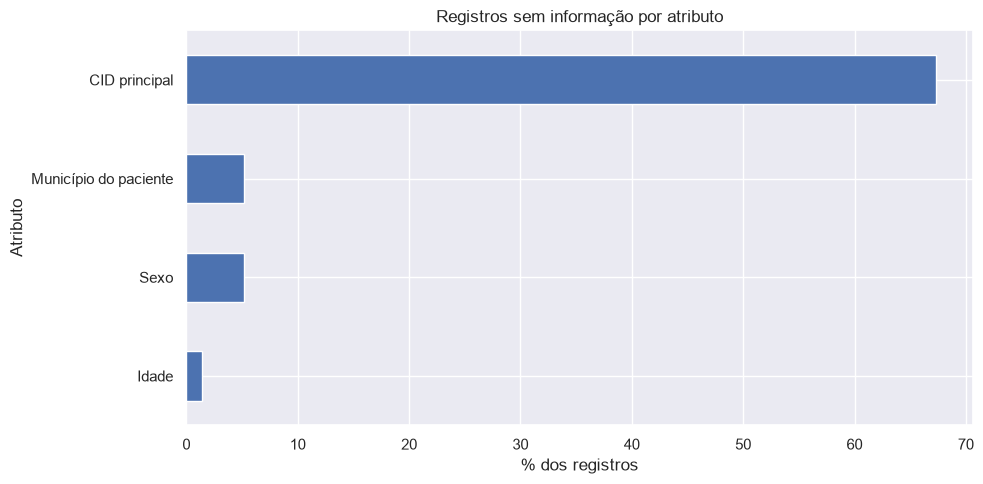

In [2]:
ausentes = pd.Series({
    "CID principal": (df["pa_cidpri"] == "0000").mean() * 100,
    "Sexo": (df["Sexo"] == "Não informado").mean() * 100,
    "Município do paciente": (df["MunicipioPaciente"] == "Não informado").mean() * 100,
    "Idade": df["IdadeNumerica"].isna().mean() * 100,
    "Ocupação": df["Ocupacao"].isna().mean() * 100,
    "Procedimento": (df["Procedimento"] == "Não informado").mean() * 100,
})
# Mantém somente os atributos que possuem registros sem informação.
ausentes = ausentes[ausentes > 0].sort_values()

ausentes.plot(kind="barh", figsize=(10, 5))
plt.title("Registros sem informação por atributo")
plt.xlabel("% dos registros")
plt.ylabel("Atributo")
mostrar("01_qualidade_dados")

**Interpretação:** o CID principal falta em **67%** dos registros; sexo e município do paciente faltam em **5%**,
sempre juntos, e a idade é inválida (999) em **1,4%**. Um campo vazio não é necessariamente erro: o BPA
consolidado não registra dados do paciente. Por isso, as análises de diagnóstico valem só para o terço
dos registros com CID, e as de perfil e origem excluem os "Não informado".

## 2. Volume e evolução temporal
### 2.1 Apresentado x aprovado - barras lado a lado

**Pergunta:** quanto foi apresentado e quanto foi aprovado pelo SUS, em quantidade e em valor?

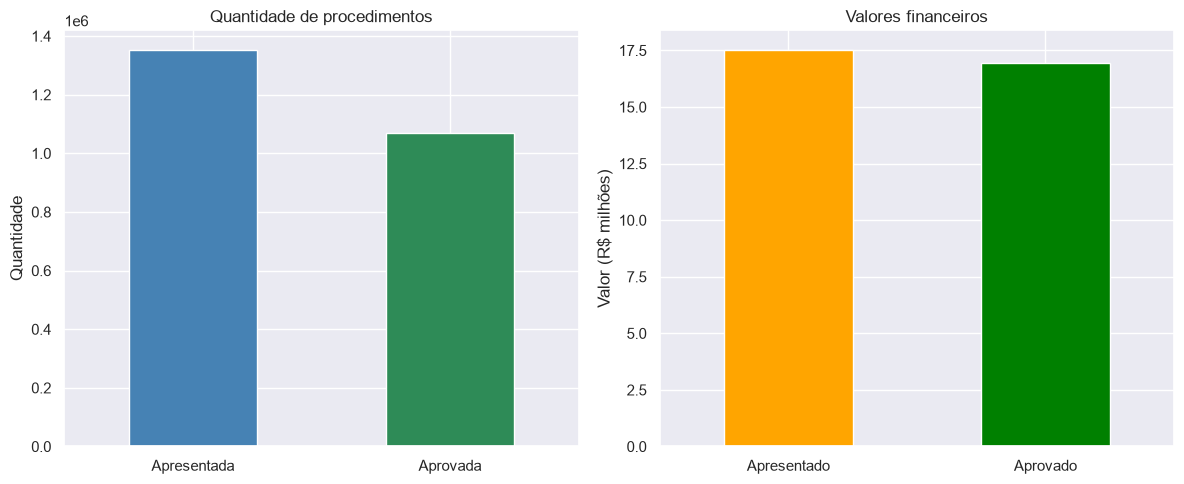

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

pd.Series({"Apresentada": df["pa_qtdpro"].sum(), "Aprovada": df["pa_qtdapr"].sum()}).plot(
    kind="bar", ax=axes[0], color=["steelblue", "seagreen"], rot=0)
axes[0].set_title("Quantidade de procedimentos")
axes[0].set_ylabel("Quantidade")

pd.Series({"Apresentado": df["pa_valpro"].sum() / 1e6, "Aprovado": df["pa_valapr"].sum() / 1e6}).plot(
    kind="bar", ax=axes[1], color=["orange", "green"], rot=0)
axes[1].set_title("Valores financeiros")
axes[1].set_ylabel("Valor (R$ milhões)")

mostrar("02_apresentado_aprovado")

**Interpretação:** foram apresentados **1,35 milhão** de procedimentos e aprovados **1,07 milhão** (79%).
Em valores, a diferença é bem menor: R$ 17,5 milhões apresentados e R$ 16,9 milhões aprovados (96,7%).
A maior parte do que não foi aprovado é de itens de baixo valor unitário, como medicamentos por comprimido.

### 2.2 Evolução mensal - gráfico de linhas

**Pergunta:** como evolui a quantidade de procedimentos apresentados e aprovados por mês?

O mês vem da DIMTEMPO ligada ao **mês de processamento** (`pa_mvm`). Com três meses, o gráfico mostra
variações pontuais, não uma tendência de longo prazo.

         pa_qtdpro  pa_qtdapr
Periodo                      
2026-06   452592.0   364022.0
2026-07   461059.0   364679.0
2026-08   437816.0   339798.0


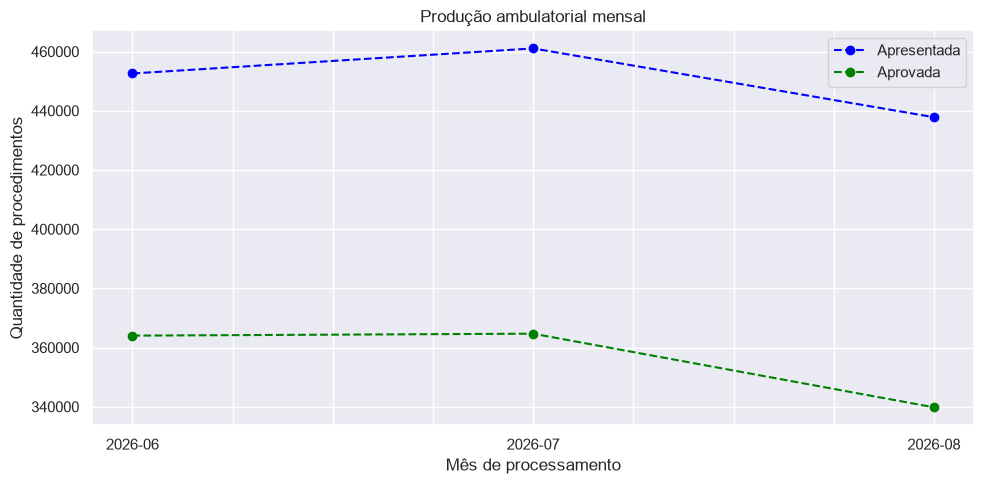

In [4]:
mensal = df.groupby("Periodo")[["pa_qtdpro", "pa_qtdapr"]].sum()
display(mensal) if "display" in globals() else print(mensal)

mensal.plot(kind="line", marker="o", linestyle="--", color=["blue", "green"], figsize=(10, 5))
plt.title("Produção ambulatorial mensal")
plt.xlabel("Mês de processamento")
plt.ylabel("Quantidade de procedimentos")
plt.legend(["Apresentada", "Aprovada"])
mostrar("03_evolucao_mensal")

**Interpretação:** a quantidade apresentada ficou estável (452 mil, 461 mil e 438 mil). A pequena queda em
agosto não indica menor demanda: CAPS, laboratórios, UPA, SAMU e Hemovita ainda não haviam enviado a produção
de agosto, e o arquivo de agosto inclui atendimentos de junho e julho processados com atraso.

### 2.3 Bimestre e trimestre - barras

**Pergunta:** como a produção aprovada se distribui nos bimestres e trimestres?

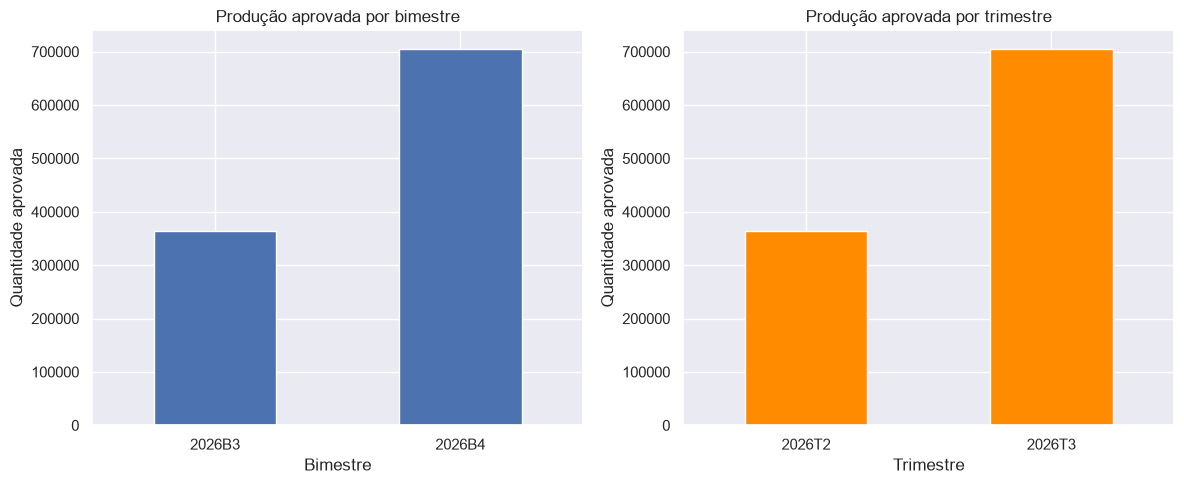

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

df.groupby("AnoBimestre")["pa_qtdapr"].sum().plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Produção aprovada por bimestre")
axes[0].set_xlabel("Bimestre")
axes[0].set_ylabel("Quantidade aprovada")

df.groupby("AnoTrimestre")["pa_qtdapr"].sum().plot(kind="bar", ax=axes[1], rot=0, color="darkorange")
axes[1].set_title("Produção aprovada por trimestre")
axes[1].set_xlabel("Trimestre")
axes[1].set_ylabel("Quantidade aprovada")

mostrar("04_bimestre_trimestre")

**Interpretação:** o 4º bimestre e o 3º trimestre somam **704 mil** procedimentos aprovados, quase o dobro do 3º
bimestre e do 2º trimestre (364 mil). A diferença vem do recorte, não da demanda: os períodos anteriores têm
só junho, enquanto os últimos têm julho e agosto. A comparação justa entre períodos é a média mensal.

### 2.4 Produção por área - barras horizontais

**Pergunta:** quais áreas concentram a quantidade de procedimentos e quais concentram os valores?

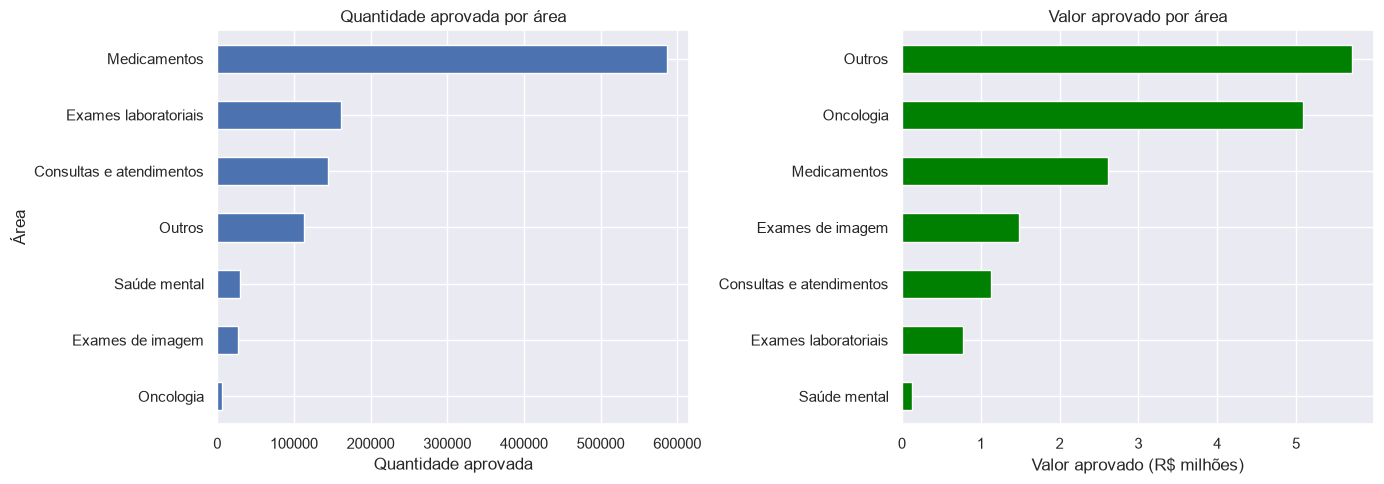

In [6]:
por_area = df.groupby("Area")[["pa_qtdapr", "pa_valapr"]].sum()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

por_area["pa_qtdapr"].sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Quantidade aprovada por área")
axes[0].set_xlabel("Quantidade aprovada")
axes[0].set_ylabel("Área")

(por_area["pa_valapr"] / 1e6).sort_values().plot(kind="barh", ax=axes[1], color="green")
axes[1].set_title("Valor aprovado por área")
axes[1].set_xlabel("Valor aprovado (R$ milhões)")
axes[1].set_ylabel("")

mostrar("05_producao_por_area")

**Interpretação:** os medicamentos são **55%** da quantidade aprovada, mas só 15% do valor. O inverso ocorre
na oncologia: **0,5%** da quantidade e **30%** do valor (R$ 5,1 milhões). Em "Outros" estão procedimentos
de alto custo, como hemodiálise, cirurgia de catarata, cateterismo cardíaco e aparelhos auditivos.
Volume e custo apontam para prioridades diferentes.

### 2.5 Evolução por área - gráfico de linhas

**Pergunta:** em quais áreas houve picos ou quedas de um mês para o outro?
Medicamentos ficam de fora porque a escala (cerca de 250 mil por mês) esconderia as demais áreas.

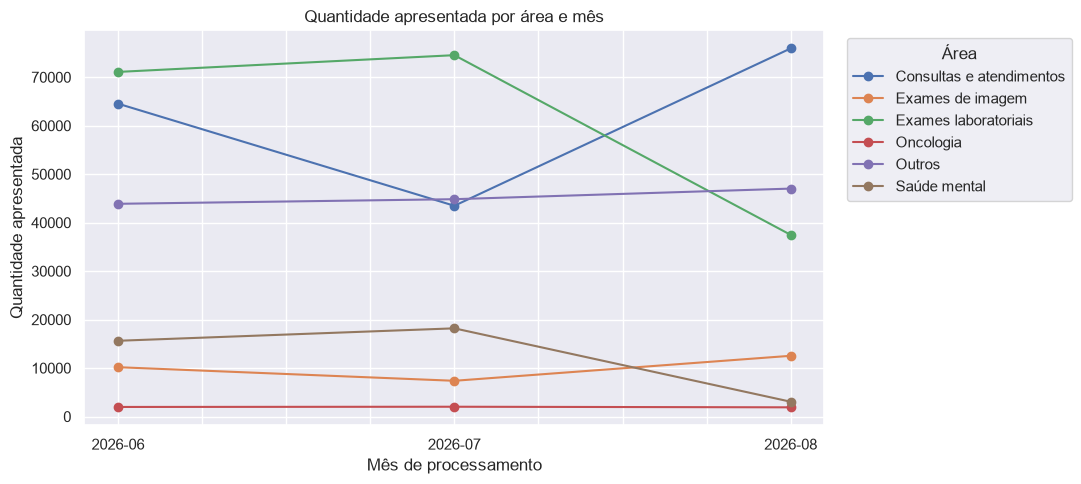

In [7]:
evolucao_area = df[df["Area"] != "Medicamentos"].pivot_table(
    index="Periodo", columns="Area", values="pa_qtdpro", aggfunc="sum")

evolucao_area.plot(kind="line", marker="o", figsize=(11, 5))
plt.title("Quantidade apresentada por área e mês")
plt.xlabel("Mês de processamento")
plt.ylabel("Quantidade apresentada")
plt.legend(title="Área", bbox_to_anchor=(1.02, 1), loc="upper left")
mostrar("06_evolucao_por_area")

**Interpretação:** as áreas com picos e quedas são as que dependem de envio atrasado. Saúde mental cai de 18 mil
para 3 mil em agosto e exames laboratoriais caem pela metade, porque os CAPS e laboratórios ainda não enviaram
agosto. Consultas e exames de imagem sobem em agosto, em parte pelos atendimentos de meses anteriores
processados nesse mês. Oncologia e "Outros" ficam estáveis.

## 3. Produção por estabelecimento - barras horizontais

**Pergunta:** quais estabelecimentos produzem mais e quais têm menor aprovação do que apresentaram?

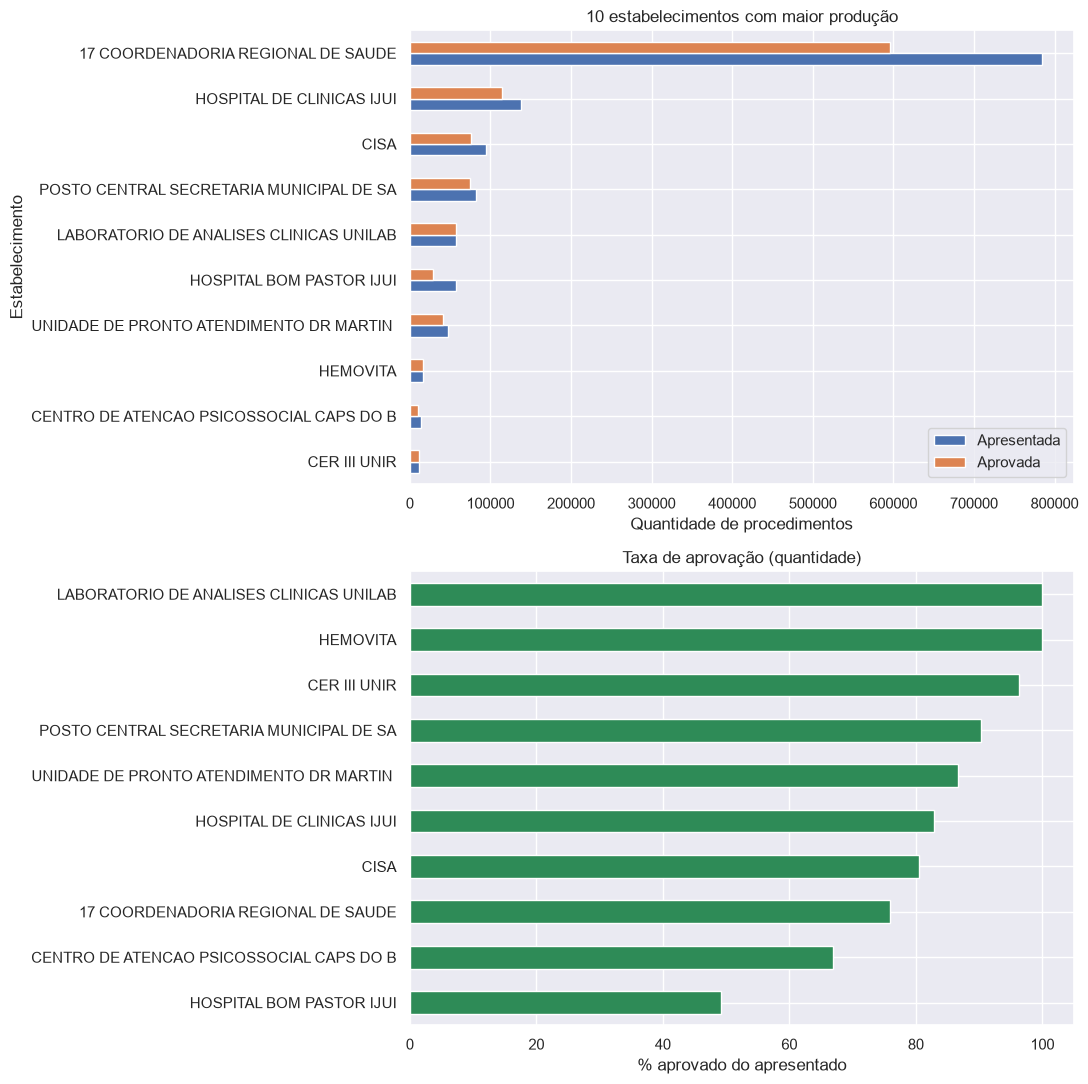

In [8]:
estabelecimentos = df.groupby("Estabelecimento")[["pa_qtdpro", "pa_qtdapr"]].sum()
estabelecimentos["Aprovacao_%"] = 100 * estabelecimentos["pa_qtdapr"] / estabelecimentos["pa_qtdpro"]
top_estab = estabelecimentos.nlargest(10, "pa_qtdpro")
top_estab.index = top_estab.index.str.slice(0, 40)

# Dois gráficos, um embaixo do outro, para caber os nomes longos.
fig, axes = plt.subplots(2, 1, figsize=(11, 11))

top_estab.sort_values("pa_qtdpro")[["pa_qtdpro", "pa_qtdapr"]].plot(kind="barh", ax=axes[0])
axes[0].set_title("10 estabelecimentos com maior produção")
axes[0].set_xlabel("Quantidade de procedimentos")
axes[0].set_ylabel("Estabelecimento")
axes[0].legend(["Apresentada", "Aprovada"])

top_estab["Aprovacao_%"].sort_values().plot(kind="barh", ax=axes[1], color="seagreen")
axes[1].set_title("Taxa de aprovação (quantidade)")
axes[1].set_xlabel("% aprovado do apresentado")
axes[1].set_ylabel("")

mostrar("07_estabelecimentos")

**Interpretação:** a 17ª Coordenadoria Regional de Saúde lidera porque dispensa medicamentos para a região,
contados por comprimido; entre os prestadores assistenciais, o Hospital de Clínicas é o maior. O Hospital Bom
Pastor tem a **menor aprovação (49%)**: os exames de oftalmologia (fundoscopia, gonioscopia etc.) foram
apresentados cerca de 5 mil vezes e aprovados cerca de 2 mil, o que sugere produção acima do limite
contratado. Laboratório Unilab e Hemovita têm 100% de aprovação.

## 4. Procedimentos e ocupações - barras horizontais

**Pergunta:** quais procedimentos e ocupações concentram a maior produção aprovada?

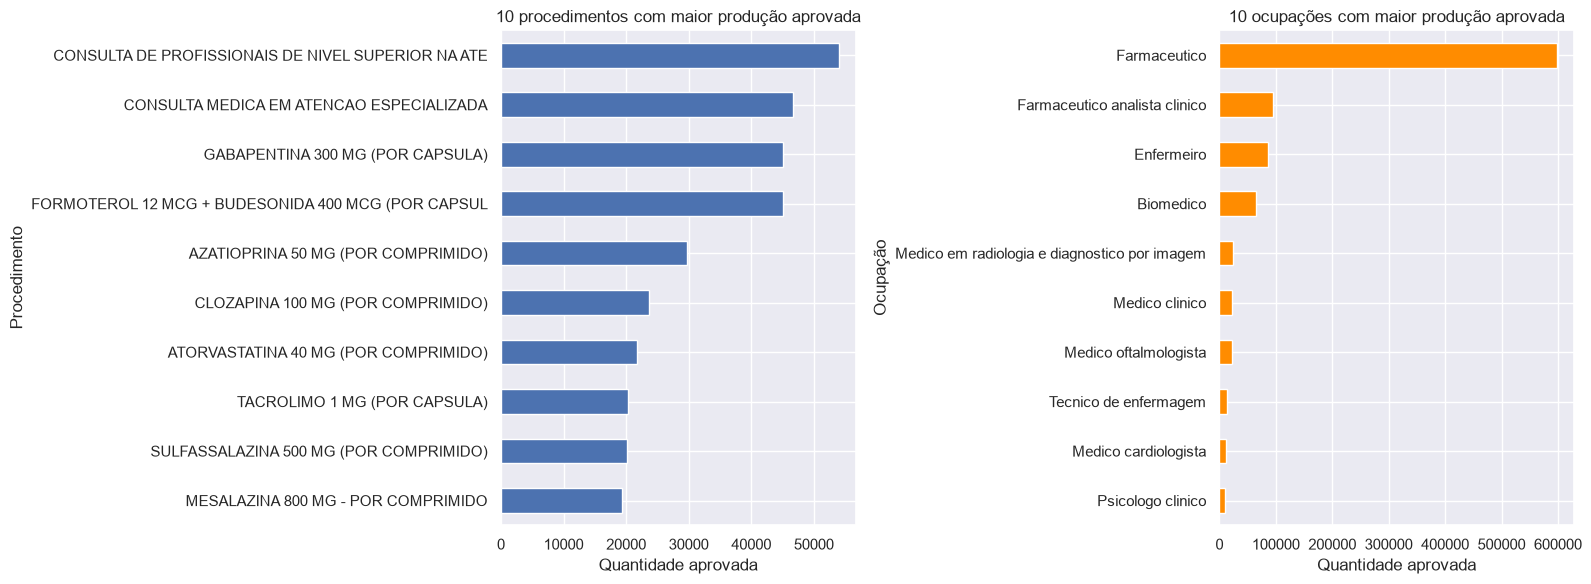

In [9]:
top_procedimentos = df.groupby("Procedimento")["pa_qtdapr"].sum().nlargest(10).sort_values()
top_procedimentos.index = top_procedimentos.index.str.slice(0, 50)
top_ocupacoes = df.groupby("Ocupacao")["pa_qtdapr"].sum().nlargest(10).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_procedimentos.plot(kind="barh", ax=axes[0])
axes[0].set_title("10 procedimentos com maior produção aprovada")
axes[0].set_xlabel("Quantidade aprovada")
axes[0].set_ylabel("Procedimento")

top_ocupacoes.plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("10 ocupações com maior produção aprovada")
axes[1].set_xlabel("Quantidade aprovada")
axes[1].set_ylabel("Ocupação")

mostrar("08_procedimentos_ocupacoes")

**Interpretação:** as consultas especializadas (médicas e de outros profissionais de nível superior) são os
procedimentos individuais mais aprovados; o restante da lista é de medicamentos para doenças crônicas
(asma/DPOC, dor crônica, colesterol, transplante, doenças inflamatórias e saúde mental). Por isso o farmacêutico aparece
com mais de **598 mil** procedimentos aprovados, muito à frente de enfermeiros e biomédicos.

## 5. Perfil demográfico e diagnósticos
### 5.1 Sexo e idade - barras e histograma

**Pergunta:** como os registros se distribuem por sexo e idade?

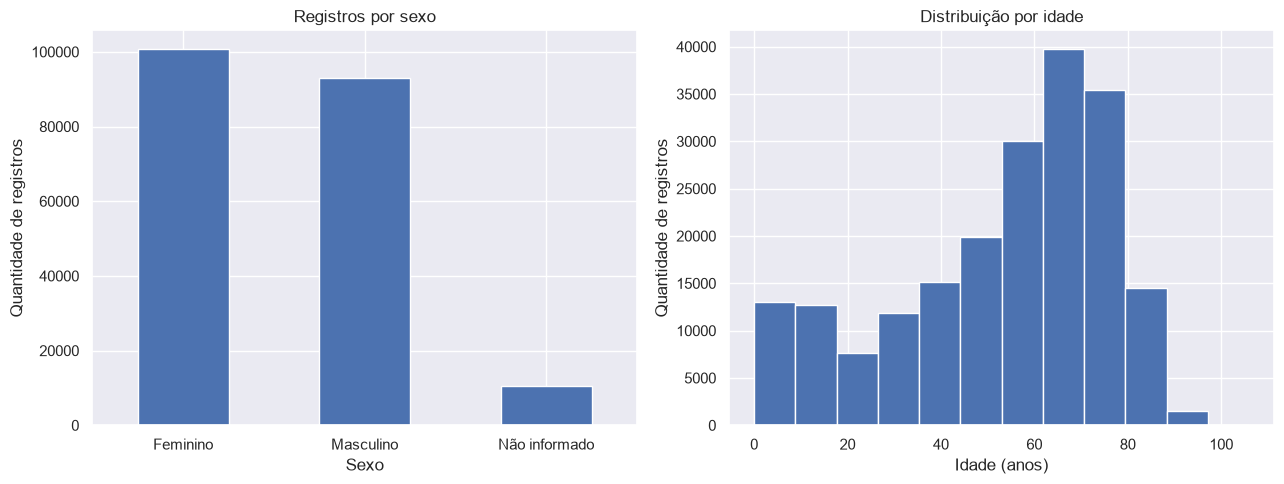

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

df["Sexo"].value_counts().plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Registros por sexo")
axes[0].set_xlabel("Sexo")
axes[0].set_ylabel("Quantidade de registros")

df["IdadeNumerica"].dropna().plot(kind="hist", bins=12, ax=axes[1])
axes[1].set_title("Distribuição por idade")
axes[1].set_xlabel("Idade (anos)")
axes[1].set_ylabel("Quantidade de registros")

mostrar("09_sexo_idade")

**Interpretação:** os registros se dividem quase igualmente entre mulheres (49%) e homens (46%); 5% não têm
sexo informado. A mediana de idade é **59 anos**, e metade dos registros está entre 39 e 71 anos.

### 5.2 Faixa etária × sexo - mapa de calor (Seaborn)

**Pergunta:** quais combinações de faixa etária e sexo concentram mais registros?
Só entram os registros com sexo e idade informados.

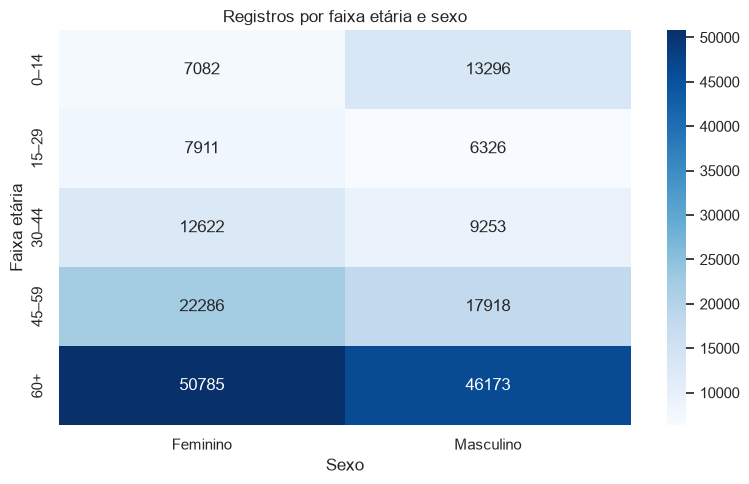

In [11]:
informados = df[(df["Sexo"] != "Não informado") & df["FaixaEtaria"].notna()]
matriz = pd.crosstab(informados["FaixaEtaria"], informados["Sexo"])

plt.figure(figsize=(8, 5))
sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues")
plt.title("Registros por faixa etária e sexo")
plt.xlabel("Sexo")
plt.ylabel("Faixa etária")
mostrar("10_faixa_etaria_sexo")

**Interpretação:** a faixa de **60 anos ou mais** concentra metade dos registros com sexo e idade
informados (97 mil de 194 mil), com predomínio feminino. Entre 0 e 14 anos o predomínio é masculino
(13 mil contra 7 mil), compatível com os atendimentos de autismo e transtornos do desenvolvimento
(CID F84), mais frequentes em meninos.

### 5.3 Diagnósticos informados - barras horizontais

**Pergunta:** quais diagnósticos (CID-10) aparecem com mais frequência nos registros com CID informado?
A contagem é de **registros**, não de pacientes.

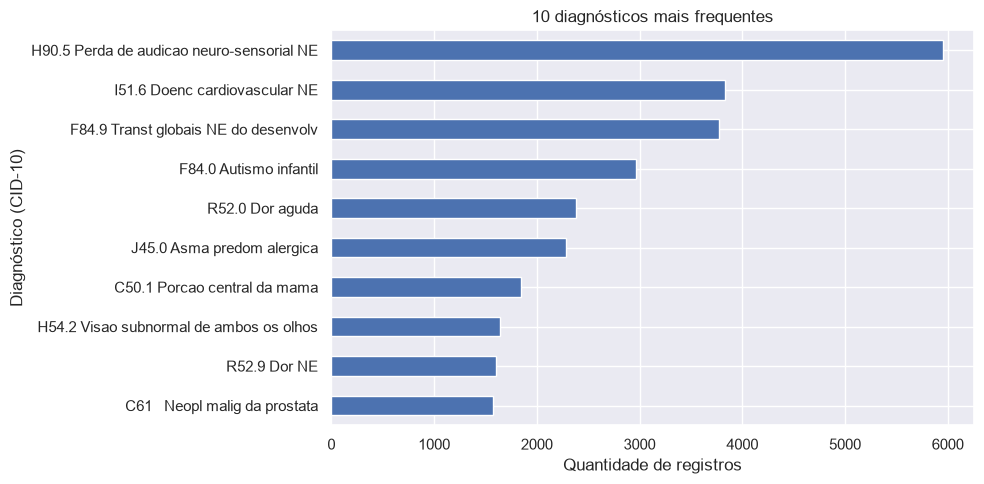

In [12]:
com_cid = df[~df["Diagnostico"].isin(["Não informado", "CID inexistente"])]
top_cid = com_cid["Diagnostico"].value_counts().head(10).sort_values()

top_cid.plot(kind="barh", figsize=(10, 5))
plt.title("10 diagnósticos mais frequentes")
plt.xlabel("Quantidade de registros")
plt.ylabel("Diagnóstico (CID-10)")
mostrar("11_diagnosticos")

**Interpretação:** entre os registros com CID, os mais frequentes são perda auditiva (H90.5), doença
cardiovascular (I51.6) e transtornos do desenvolvimento e autismo (F84). Aparecem também câncer de mama (C50)
e de próstata (C61). Hipertensão e diabetes quase não aparecem, porque o acompanhamento dessas doenças é feito
na atenção básica, que não registra no SIASUS.

## 6. Fluxos regionais - barras

**Pergunta:** quanto da produção de Ijuí atende moradores de outros municípios, e de quais?

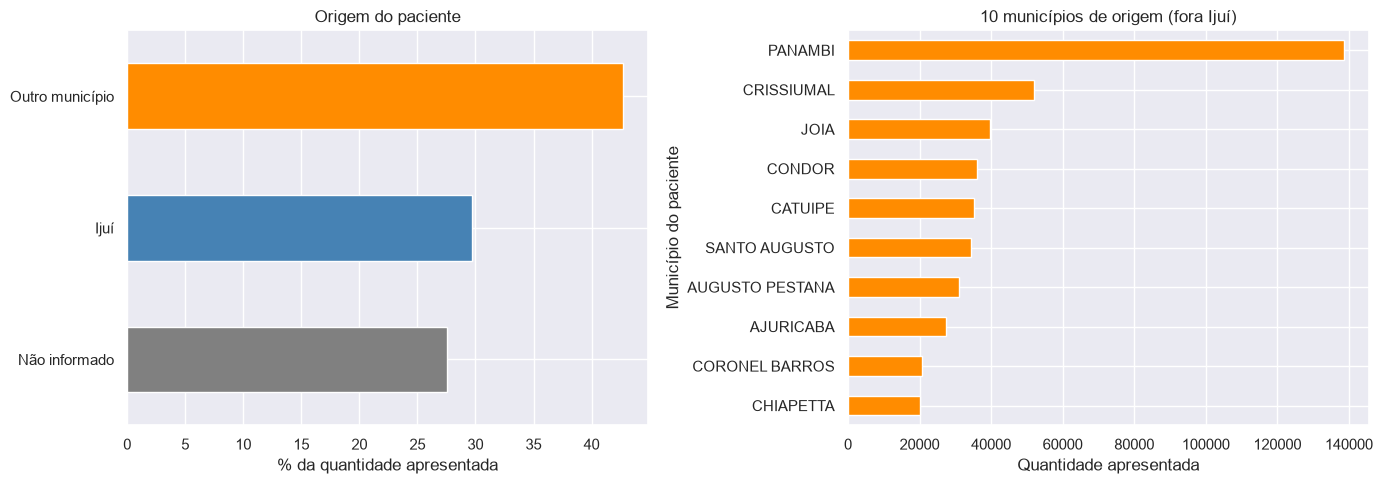

In [13]:
origem = df.groupby("Origem")["pa_qtdpro"].sum().sort_values()
top_municipios = (df[df["Origem"] == "Outro município"].groupby("MunicipioPaciente")["pa_qtdpro"].sum()
                  .nlargest(10).sort_values())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

(100 * origem / origem.sum()).plot(kind="barh", ax=axes[0], color=["gray", "steelblue", "darkorange"])
axes[0].set_title("Origem do paciente")
axes[0].set_xlabel("% da quantidade apresentada")
axes[0].set_ylabel("")

top_municipios.plot(kind="barh", ax=axes[1], color="darkorange")
axes[1].set_title("10 municípios de origem (fora Ijuí)")
axes[1].set_xlabel("Quantidade apresentada")
axes[1].set_ylabel("Município do paciente")

mostrar("12_fluxos_regionais")

**Interpretação:** **43%** da quantidade apresentada é de moradores de outros municípios, contra 30% de
moradores de Ijuí (28% sem município informado). São 244 municípios de origem, com destaque para Panambi,
Crissiumal, Joia, Condor e Catuípe. Ijuí funciona como polo regional, o que afeta o planejamento da oferta
e do financiamento.

## 7. Recursos financeiros - barras e linhas

**Pergunta:** qual a diferença entre valores apresentados e aprovados, e como evolui o gasto médio
por procedimento?

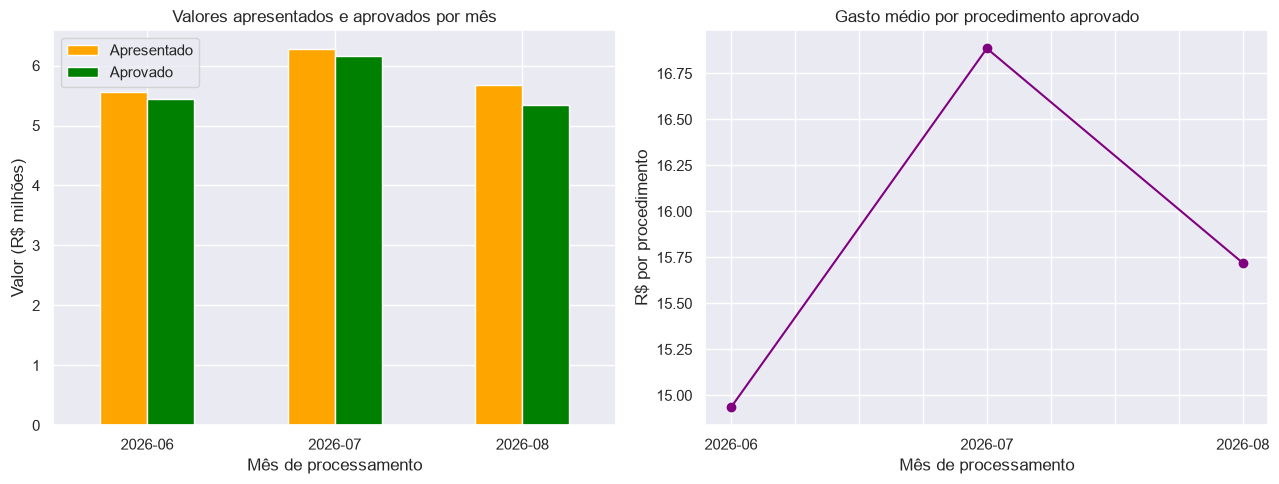

In [14]:
financeiro = df.groupby("Periodo")[["pa_valpro", "pa_valapr", "pa_qtdapr"]].sum()
financeiro["GastoMedio"] = financeiro["pa_valapr"] / financeiro["pa_qtdapr"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

(financeiro[["pa_valpro", "pa_valapr"]] / 1e6).plot(kind="bar", ax=axes[0], rot=0, color=["orange", "green"])
axes[0].set_title("Valores apresentados e aprovados por mês")
axes[0].set_xlabel("Mês de processamento")
axes[0].set_ylabel("Valor (R$ milhões)")
axes[0].legend(["Apresentado", "Aprovado"])

financeiro["GastoMedio"].plot(kind="line", marker="o", ax=axes[1], color="purple")
axes[1].set_title("Gasto médio por procedimento aprovado")
axes[1].set_xlabel("Mês de processamento")
axes[1].set_ylabel("R$ por procedimento")

mostrar("13_financeiro")

**Interpretação:** a diferença entre apresentado e aprovado é pequena em junho e julho (cerca de 2%) e maior em
agosto (**R$ 335 mil**, 5,9%). O gasto médio por procedimento aprovado varia pouco (R$ 14,93, R$ 16,89 e
R$ 15,72); o eixo vertical do gráfico não começa em zero e amplia visualmente essa variação.

## 8. Áreas críticas
### 8.1 Oncologia e saúde mental - barras

**Pergunta:** quanto foi apresentado e aprovado em quimioterapia e radioterapia, e como evoluem os
atendimentos de saúde mental por mês?

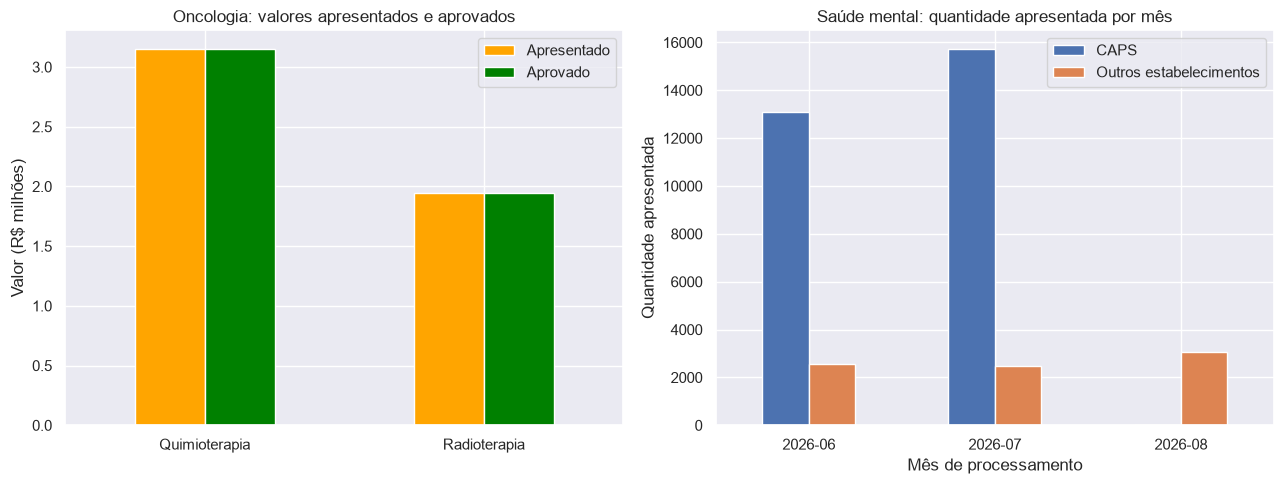

In [15]:
onco = df[df["Area"] == "Oncologia"].copy()
onco["Modalidade"] = "Quimioterapia"
onco.loc[onco["Procedimento"].str.contains("RADIOTERAPIA|BRAQUITERAPIA|BETATERAPIA"), "Modalidade"] = "Radioterapia"
oncologia = onco.groupby("Modalidade")[["pa_valpro", "pa_valapr"]].sum() / 1e6

sm = df[df["Area"] == "Saúde mental"].copy()
sm["Tipo"] = "Outros estabelecimentos"
sm.loc[sm["Estabelecimento"].str.contains("CAPS"), "Tipo"] = "CAPS"
saude_mental = sm.pivot_table(index="Periodo", columns="Tipo", values="pa_qtdpro", aggfunc="sum", fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

oncologia.plot(kind="bar", ax=axes[0], rot=0, color=["orange", "green"])
axes[0].set_title("Oncologia: valores apresentados e aprovados")
axes[0].set_xlabel("")
axes[0].set_ylabel("Valor (R$ milhões)")
axes[0].legend(["Apresentado", "Aprovado"])

saude_mental.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Saúde mental: quantidade apresentada por mês")
axes[1].set_xlabel("Mês de processamento")
axes[1].set_ylabel("Quantidade apresentada")
axes[1].legend(title="")

mostrar("14_oncologia_saude_mental")

**Interpretação:** toda a oncologia é feita no Hospital de Clínicas: R$ 3,1 milhões em quimioterapia e
R$ 1,9 milhão em radioterapia, com praticamente **100% de aprovação**. Na saúde mental, os CAPS respondem pela
maior parte da produção em junho e julho e não têm registros em agosto: o arquivo ainda não traz a produção
deles. Para avaliar a saúde mental, é preciso aguardar o envio de agosto.

## 9. Conclusões para a gestão municipal

* **Polo regional:** 43% da produção atende moradores de outros municípios, principalmente
  Panambi. Isso deve ser considerado na pactuação e no financiamento.
* **Custo concentrado:** oncologia (0,5% da quantidade, 30% do valor) e procedimentos de alto custo, como
  hemodiálise, definem o orçamento; medicamentos definem o volume.
* **Glosas:** o Hospital Bom Pastor teve 49% de aprovação, concentrada em exames de oftalmologia. Vale
  verificar o limite contratado.
* **População idosa:** pessoas com 60 anos ou mais são metade dos registros com sexo e idade informados.
* **Qualidade dos dados:** 67% dos registros não têm CID, e agosto está incompleto (CAPS, laboratórios,
  UPA). As comparações mensais devem ser refeitas quando o DATASUS publicar os envios atrasados.
* **Atenção básica:** as UBS não registram no SIASUS. Para avaliar consultas na atenção primária e o
  acompanhamento de hipertensão e diabetes, é preciso usar os dados do e-SUS APS / SISAB.